# Notebook 8 – Distribution Analysis

**Sprint 4 – Data Inspection & Exploratory Data Analysis**  
Workflow: `Load → Inspect → Understand → Analyze → Visualize → Identify Problems → Document Findings`  
**Dataset:** Telco Customer Churn (IBM sample data, 7,043 customers × 21 columns)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Load the RAW dataset (nothing has been modified yet)
PATH = "../data/telco.csv"
if not os.path.exists(PATH):   # fallback: download straight from the public source
    PATH = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df_raw = pd.read_csv(PATH)
df = df_raw.copy()
print("Loaded:", df.shape)

# NOTE: 'TotalCharges' is stored as text in the raw file (11 blank strings, see 03_Data_Quality).
# For ANALYSIS ONLY we create a numeric working copy; blanks become NaN. The raw file is untouched,
# and the formal treatment of these rows is deferred to the preprocessing sprint.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID"]]
target = "Churn"
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)   # helper for rates/correlations (analysis only)

Loaded: (7043, 21)


### Topic Explanation

This topic describes the shape of values, including symmetry, skewness, centre, spread, and tail behaviour.

## 1. Distribution Concepts (reference)

| Concept | Meaning |
|---|---|
| **Normal** | Symmetric bell shape; mean = median = mode; ≈ 68/95/99.7% within 1/2/3 σ |
| **Uniform** | All values in a range equally likely (flat) |
| **Symmetric** | Left half mirrors right half; skewness ≈ 0 |
| **Right-skewed (positive)** | Long right tail; mean > median |
| **Left-skewed (negative)** | Long left tail; mean < median |
| **Skewness** | Asymmetry measure (0 = symmetric) |
| **Kurtosis (excess)** | Tail heaviness (0 normal, > 0 heavy tails/peaked, < 0 light tails/flat) |

### Topic Explanation

This topic checks dataset size, field names, and row indexing to understand its structure.

## 2. Reference shapes (synthetic)

### 1. Concept
Generate each distribution to *see* what shape, centre, spread and skewness look like before judging real data.

### 2. Example
*Simple:* heights ≈ normal; dice rolls ≈ uniform; incomes ≈ right-skewed; exam marks on an easy test ≈ left-skewed.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

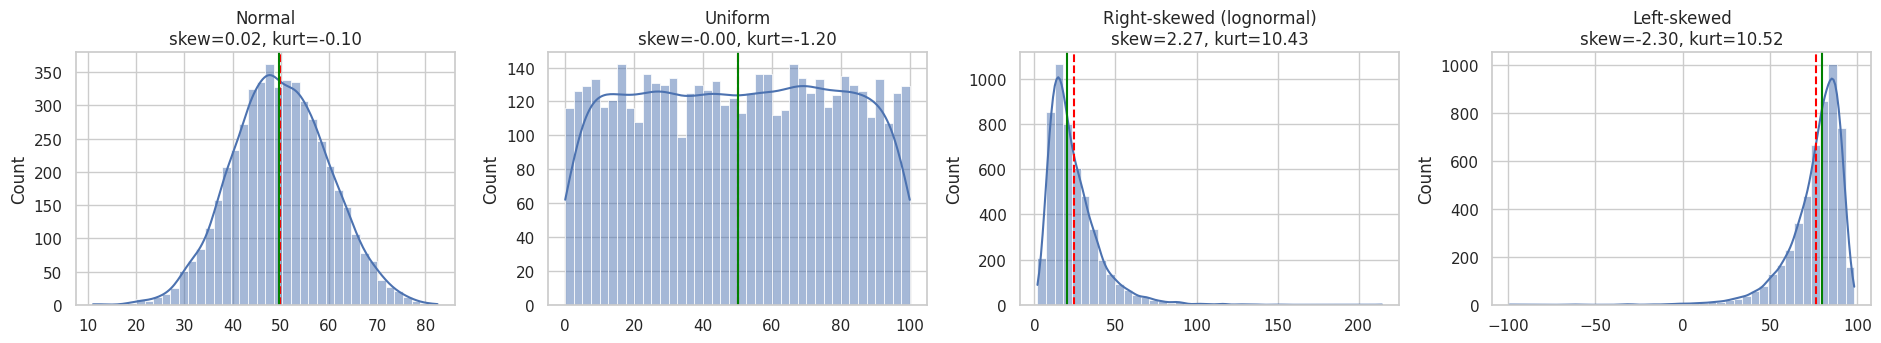

In [2]:
rng = np.random.default_rng(0)
samples = {
    "Normal": rng.normal(50, 10, 5000),
    "Uniform": rng.uniform(0, 100, 5000),
    "Right-skewed (lognormal)": rng.lognormal(3, 0.6, 5000),
    "Left-skewed": 100 - rng.lognormal(3, 0.6, 5000),
}
fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
for ax, (name, s) in zip(axes, samples.items()):
    s = pd.Series(s)
    sns.histplot(s, kde=True, ax=ax, bins=40)
    ax.axvline(s.mean(), color="red", ls="--"); ax.axvline(s.median(), color="green")
    ax.set_title(f"{name}\nskew={s.skew():.2f}, kurt={s.kurt():.2f}")
plt.tight_layout(); plt.show()

### 5. Interpretation
Normal: skew ≈ 0, kurtosis ≈ 0. Uniform: skew ≈ 0 but kurtosis ≈ –1.2 (flat). Right-skewed: skew > 0, mean (red) to the right of the median (green). Left-skewed: the mirror image.

### 6. Insight
Skewness alone does not describe a shape: uniform and normal have the same skewness but different kurtosis.

### 7. AI/ML Relevance
These templates help identify the shape of real features and choose transformations (log for right-skew).

### Topic Explanation

This topic distinguishes input features used for analysis from the target variable the analysis may aim to explain or predict.

## 3. Distribution of Telco Numerical Features – Shape, Centre, Spread

### 1. Concept
For each important numerical feature report centre (mean/median), spread (std/IQR), skewness, kurtosis, and use a histogram+KDE and a **Q-Q plot** (points on the line → normal).

### 2. Example
Business: understand how bills and customer lifetimes are distributed.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

In [3]:
rows = []
for c in num_cols:
    s = df[c].dropna()
    rows.append((c, s.mean(), s.median(), s.std(), s.quantile(.75) - s.quantile(.25), s.skew(), s.kurt()))
dist = pd.DataFrame(rows, columns=["feature", "mean", "median", "std", "IQR", "skew", "excess_kurtosis"]).set_index("feature").round(2)
dist["shape_label"] = ["Uniform-like / U-shaped, near-symmetric", "Bimodal, slightly left-skewed", "Right-skewed"]
dist

,mean,median,std,IQR,skew,excess_kurtosis,shape_label
feature,,,,,,,
tenure,32.37,29.00,24.56,46.00,0.24,-1.39,"Uniform-like / U-shaped, near-symmetric"
MonthlyCharges,64.76,70.35,30.09,54.35,-0.22,-1.26,"Bimodal, slightly left-skewed"
TotalCharges,2283.30,1397.48,2266.77,3393.29,0.96,-0.23,Right-skewed


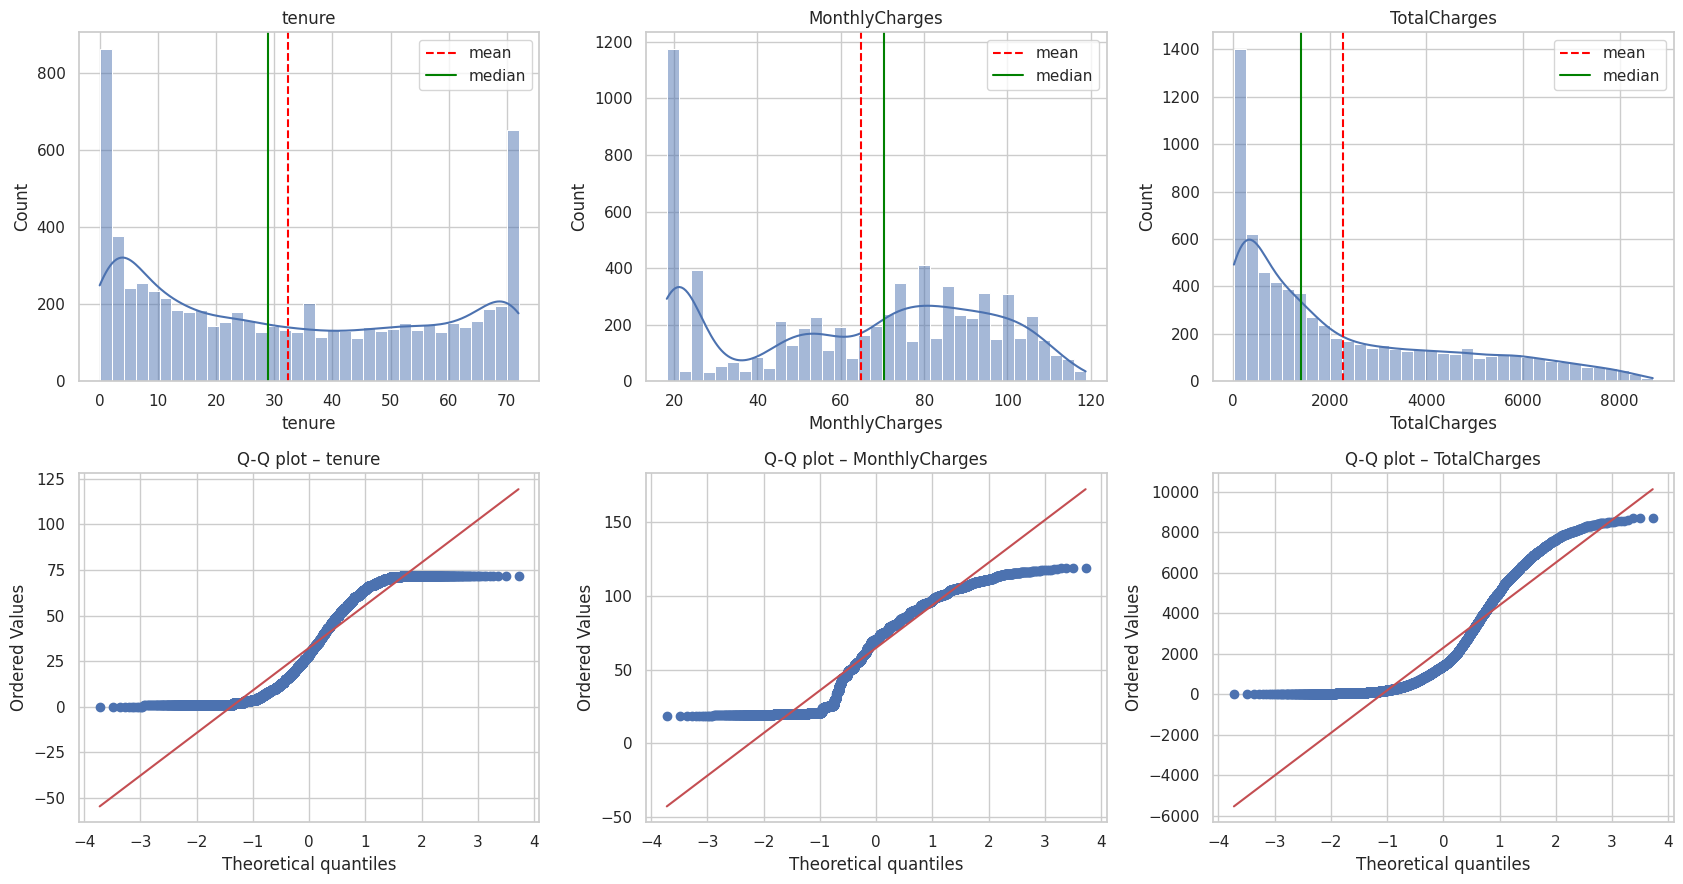

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for i, c in enumerate(num_cols):
    s = df[c].dropna()
    sns.histplot(s, kde=True, bins=35, ax=axes[0, i]); axes[0, i].set_title(f"{c}")
    axes[0, i].axvline(s.mean(), color="red", ls="--", label="mean"); axes[0, i].axvline(s.median(), color="green", label="median"); axes[0, i].legend()
    stats.probplot(s, dist="norm", plot=axes[1, i]); axes[1, i].set_title(f"Q-Q plot – {c}")
plt.tight_layout(); plt.show()

In [5]:
# normality tests (D'Agostino K²; Shapiro is reserved for n < 5000)
for c in num_cols:
    k2, p = stats.normaltest(df[c].dropna())
    print(f"{c:<15} K²={k2:10.1f}  p={p:.2e}  ->", "reject normality" if p < 0.05 else "cannot reject normality")

tenure          K²=   76258.5  p=0.00e+00  -> reject normality
MonthlyCharges  K²=   11419.5  p=0.00e+00  -> reject normality
TotalCharges    K²=     806.0  p=9.61e-176  -> reject normality


### 5. Interpretation
- **tenure** – centre ≈ 29–32, spread std ≈ 24.6, skew ≈ 0.24, kurtosis ≈ –1.4: *flat, U-shaped, near-symmetric*; the Q-Q plot is S-shaped.  
- **MonthlyCharges** – centre ≈ 65–70, std ≈ 30, skew ≈ –0.22, kurtosis ≈ –1.26: *bimodal* (≈ \$20 and ≈ \$80); Q-Q shows a step.  
- **TotalCharges** – mean 2,283 ≫ median 1,397, skew ≈ 0.96: *right-skewed*; Q-Q curves upward at the right.  
All three formally **reject normality** (p ≈ 0).

### 6. Insight
None of the numeric features is normal. Summary statistics like the mean are misleading for the bimodal `MonthlyCharges` – it describes neither of the two customer groups.

### 7. AI/ML Relevance
Models assuming normality (LDA, some statistical tests, linear regression residuals) need care; tree models are indifferent. Transform or segment before using linear models.

### Topic Explanation

This topic focuses on effect of a log transform on a right-skewed feature (demonstration only). Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 4. Effect of a Log Transform on a Right-Skewed Feature (demonstration only)

### 1. Concept
A log (or `log1p`) transform compresses the long right tail and makes a right-skewed variable more symmetric. This is shown only to *document a possible next step*; the data is not changed.

### 2. Example
*Simple:* comparing incomes on a log scale makes millionaires and wage earners fit on one chart.

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

skew original=0.96  sqrt=0.31  log1p=-0.74


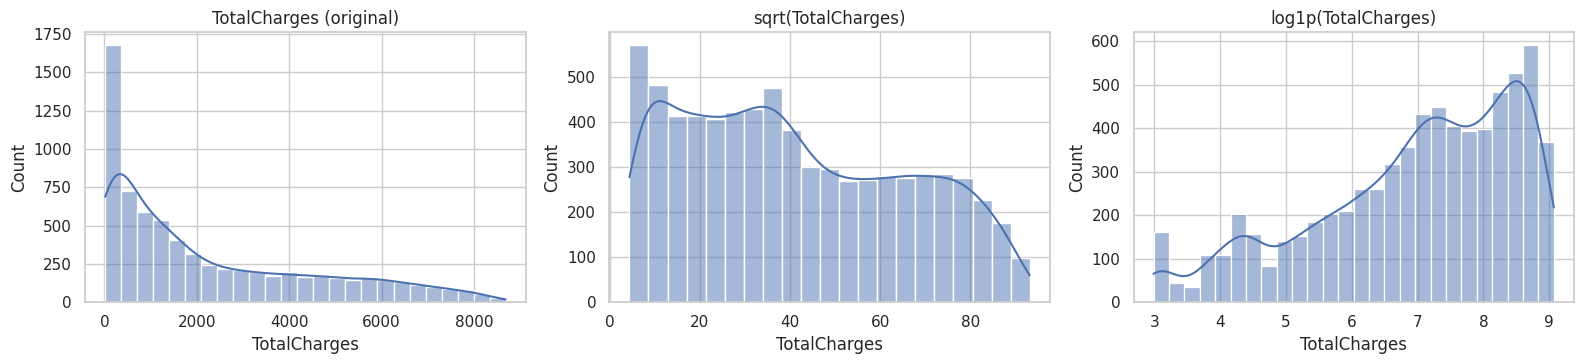

In [6]:
s = df["TotalCharges"].dropna()
logged = np.log1p(s)
sqrt = np.sqrt(s)
print(f"skew original={s.skew():.2f}  sqrt={sqrt.skew():.2f}  log1p={logged.skew():.2f}")
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(s, kde=True, ax=axes[0]).set_title("TotalCharges (original)")
sns.histplot(sqrt, kde=True, ax=axes[1]).set_title("sqrt(TotalCharges)")
sns.histplot(logged, kde=True, ax=axes[2]).set_title("log1p(TotalCharges)")
plt.tight_layout(); plt.show()

### 5. Interpretation
Skewness drops from about 0.96 to about 0.3 (square root) and then becomes *negative* (≈ –0.7) for `log1p`, because many customers with very small totals now form a left tail. The square root is the better fit here.

### 6. Insight
A transform that fixes one tail can create another; choose by testing, not by habit. For `TotalCharges`, sqrt corrects the skew better than log.

### 7. AI/ML Relevance
Transformations are an important preprocessing step, but they must be validated; they are listed as recommendations for the next sprint.

### Topic Explanation

This topic describes the shape of values, including symmetry, skewness, centre, spread, and tail behaviour.

## 5. Distribution by Churn Group

### 1. Concept
Compare shape across target classes: overlapping distributions mean a weak separator; shifted distributions mean a useful feature.

### 2. Example
Business: do churners and stayers have different tenure/bill profiles?

### 3. Implementation & 4. Output
*(code below, output printed under each cell)*

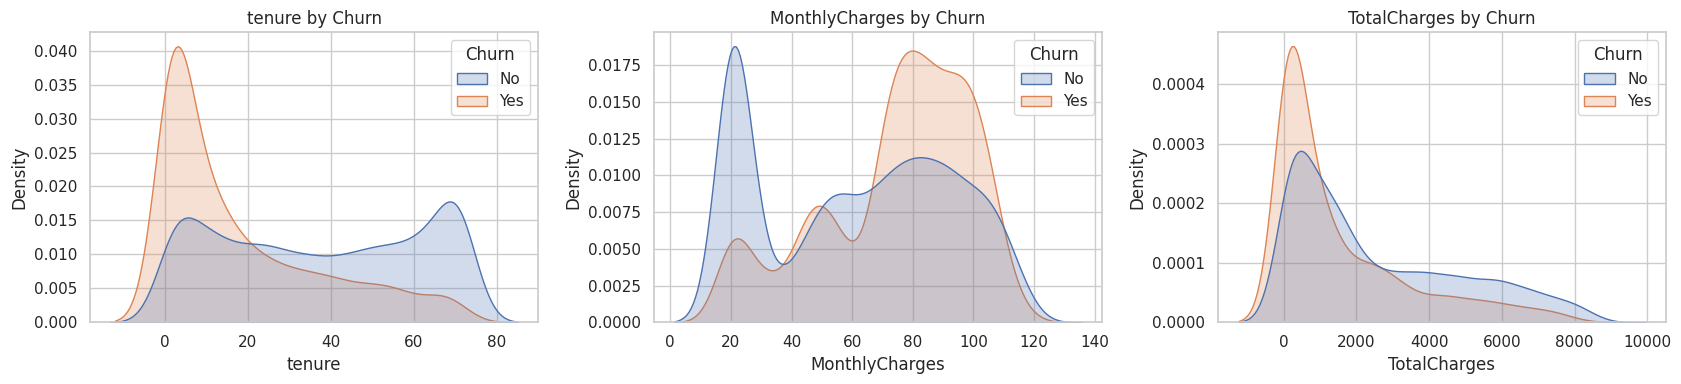

      tenure              MonthlyCharges              TotalCharges               
        mean median  skew           mean median  skew         mean   median  skew
Churn                                                                            
No     37.57   38.0 -0.03          61.27  64.43 -0.03      2555.34  1683.60  0.81
Yes    17.98   10.0  1.15          74.44  79.65 -0.73      1531.80   703.55  1.51


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, c in zip(axes, num_cols):
    sns.kdeplot(data=df, x=c, hue="Churn", fill=True, common_norm=False, ax=ax)
    ax.set_title(f"{c} by Churn")
plt.tight_layout(); plt.show()
print(df.groupby("Churn")[num_cols].agg(["mean", "median", "skew"]).round(2))

### 5. Interpretation
Churners' tenure distribution is heavily concentrated at the low end (peak at 1–5 months) while non-churners are spread across the full range with a second peak at 72. Churners' `MonthlyCharges` shifts toward the high-price hump; `TotalCharges` for churners is concentrated at low values.

### 6. Insight
`tenure` shows the clearest distributional difference between classes.

### 7. AI/ML Relevance
Features whose class-conditional distributions differ are likely to be important predictors.